In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import warnings
warnings.filterwarnings("ignore")

In [3]:
cd C:\Users\faizp\Downloads\projects

C:\Users\faizp\Downloads\projects


In [4]:
data=pd.read_csv(r"train.csv")

In [5]:
data

,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.000,0
1,1,2013-01-01,1,BABY CARE,0.000,0
2,2,2013-01-01,1,BEAUTY,0.000,0
3,3,2013-01-01,1,BEVERAGES,0.000,0
4,4,2013-01-01,1,BOOKS,0.000,0
...,...,...,...,...,...,...
3000883,3000883,2017-08-15,9,POULTRY,438.133,0
3000884,3000884,2017-08-15,9,PREPARED FOODS,154.553,1
3000885,3000885,2017-08-15,9,PRODUCE,2419.729,148
3000886,3000886,2017-08-15,9,SCHOOL AND OFFICE SUPPLIES,121.000,8


In [6]:
data.head()

,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


In [7]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000888 entries, 0 to 3000887
Data columns (total 6 columns):
 #   Column       Dtype  
---  ------       -----  
 0   id           int64  
 1   date         str    
 2   store_nbr    int64  
 3   family       str    
 4   sales        float64
 5   onpromotion  int64  
dtypes: float64(1), int64(3), str(2)
memory usage: 137.4 MB


In [8]:
data.describe()

,id,store_nbr,sales,onpromotion
count,3.000888e+06,3.000888e+06,3.000888e+06,3.000888e+06
mean,1.500444e+06,2.750000e+01,3.577757e+02,2.602770e+00
std,8.662819e+05,1.558579e+01,1.101998e+03,1.221888e+01
min,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00
25%,7.502218e+05,1.400000e+01,0.000000e+00,0.000000e+00
50%,1.500444e+06,2.750000e+01,1.100000e+01,0.000000e+00
75%,2.250665e+06,4.100000e+01,1.958473e+02,0.000000e+00
max,3.000887e+06,5.400000e+01,1.247170e+05,7.410000e+02


In [98]:
data.drop(columns=['id'], inplace=True)

In [10]:
data.isnull().sum()

id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64

In [11]:
data.isnull().sum() / len(data) * 100

id             0.0
date           0.0
store_nbr      0.0
family         0.0
sales          0.0
onpromotion    0.0
dtype: float64

In [12]:
data.duplicated().sum()

np.int64(0)

In [13]:
data['date'] = pd.to_datetime(data['date'])

In [14]:
data['date'].dtype

dtype('<M8[us]')

In [15]:
data['year']=data['date'].dt.year
data['month']=data['date'].dt.month
data['day']=data['date'].dt.day
data['dayofweek']=data['date'].dt.dayofweek

In [16]:
total_sales=data['sales'].sum()

In [17]:
print(data['sales'].mean())

357.77574911261877


In [18]:
print(data['sales'].max())

124717.0


In [19]:
print(data['sales'].min())

0.0


In [27]:
data.head()

,id,date,store_nbr,family,sales,onpromotion,year,month,day,dayofweek
0,<bound method Series.drop of 0 ...,2013-01-01,1,0,0.0,0,2013,1,1,1
1,<bound method Series.drop of 0 ...,2013-01-01,1,1,0.0,0,2013,1,1,1
2,<bound method Series.drop of 0 ...,2013-01-01,1,2,0.0,0,2013,1,1,1
3,<bound method Series.drop of 0 ...,2013-01-01,1,3,0.0,0,2013,1,1,1
4,<bound method Series.drop of 0 ...,2013-01-01,1,4,0.0,0,2013,1,1,1


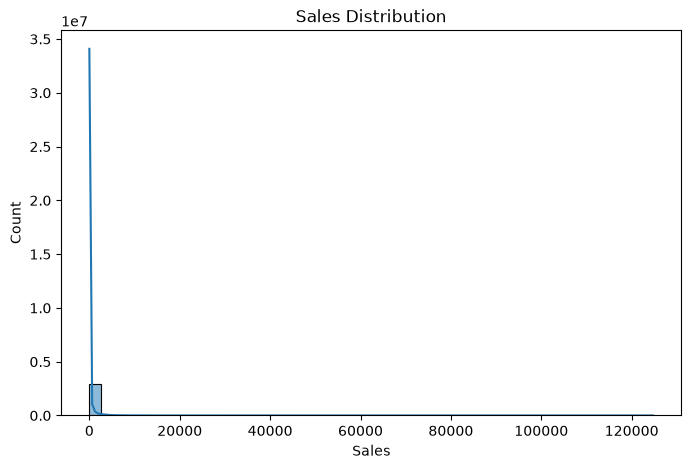

In [28]:
plt.figure(figsize=(8,5))
sns.histplot(data['sales'], bins=50, kde=True)
plt.title("Sales Distribution")
plt.xlabel("Sales")
plt.show()

In [33]:
family_sales = data.groupby('family')['sales'].sum()
family_sales = family_sales.sort_values(ascending=False)

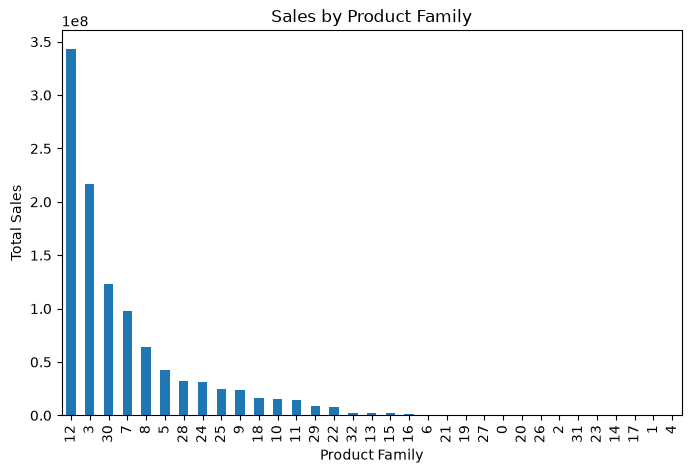

In [34]:
plt.figure(figsize=(8,5))
family_sales.plot(kind='bar')
plt.title("Sales by Product Family")
plt.xlabel("Product Family")
plt.ylabel("Total Sales")
plt.show()

In [36]:
store_sales = data.groupby('store_nbr')['sales'].sum()
store_sales = store_sales.sort_values(ascending=False)

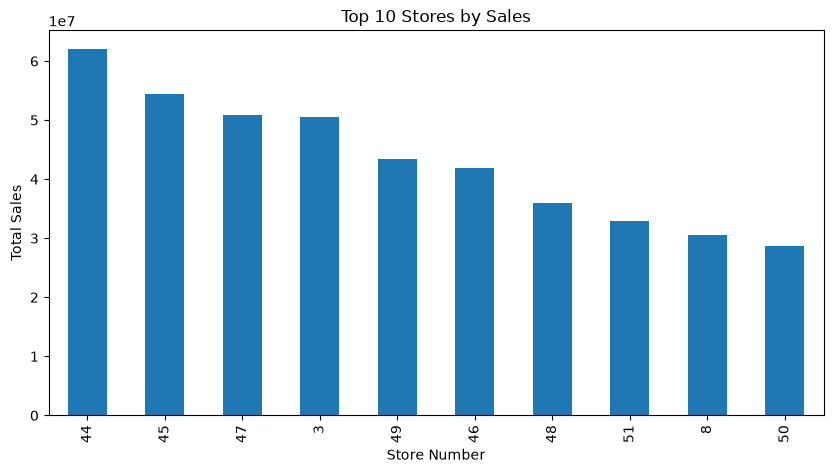

In [37]:
plt.figure(figsize=(10,5))
store_sales.head(10).plot(kind='bar')
plt.title("Top 10 Stores by Sales")
plt.xlabel("Store Number")
plt.ylabel("Total Sales")
plt.show()

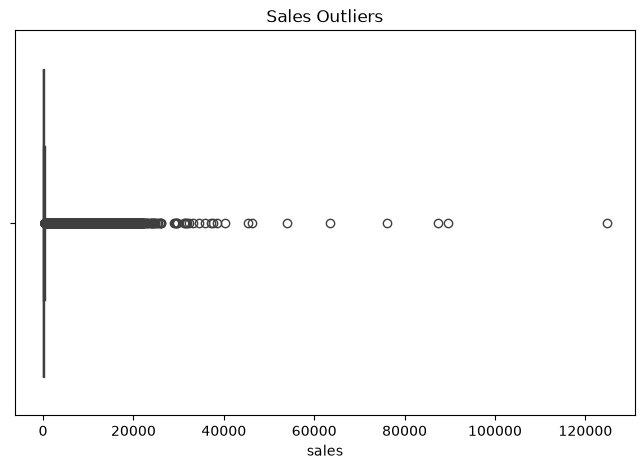

In [42]:
plt.figure(figsize=(8,5))
sns.boxplot(x=data['sales'])
plt.title("Sales Outliers")
plt.show()

In [46]:
Q1 = data['sales'].quantile(0.25)
Q3 = data['sales'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR

upper = Q3 + 1.5 * IQR

outliers = data[
    (data['sales'] < lower) |
    (data['sales'] > upper)
]

In [47]:
len(outliers)

447105

In [99]:
# sales has some outlier but sale could be high in some month and low also thats why we cannot see this as outlier

In [21]:
from sklearn.preprocessing import LabelEncoder

In [23]:
le = LabelEncoder()

In [24]:
data['family'] = le.fit_transform(data['family'])

In [48]:
data[['family']].head()

,family
0,0
1,1
2,2
3,3
4,4


In [26]:
x = data[[ 'store_nbr','family','onpromotion','year','month','day','dayofweek']]
y = data['sales']

In [52]:
data=data.sort_values("date")

In [53]:
from sklearn.model_selection import train_test_split

In [54]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [55]:
x_train.shape

(2400710, 7)

In [57]:
x_test.shape

(600178, 7)

# LinearRegression

In [58]:
from sklearn.linear_model import LinearRegression

In [59]:
model=LinearRegression()

In [60]:
model.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](7,)","[ 2.67,-10.95, 38.08,..., 2.86, -1.6 , 20.74]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](7,)","['store_nbr','family','onpromotion',...,'month','day','dayofweek']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,3700
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,7


In [62]:
yp=model.predict(x_test)

In [65]:
yp

array([2738.90023773,  359.23038189,  338.23289956, ...,  325.56533512,
        497.77802194,  420.81959679], shape=(600178,))

# RandomForestRegressor

In [73]:
from sklearn.ensemble import RandomForestRegressor

In [77]:
model2=RandomForestRegressor()

In [78]:
model2.fit(x_train,y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the numb

In [85]:
yp2=model2.predict(x_test)

In [86]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

In [100]:
# create function and evaluate all model in simple way so we didnt write code two times 

In [90]:
def evaluate_model(y_test,yp):
    mae = mean_absolute_error(y_test, yp)
    mse = mean_squared_error(y_test, yp)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, yp)
    print(mae)
    print(mse)
    print(rmse)
    print(r2)

In [92]:
print("Linear Regression Results")
evaluate_model(y_test,yp)

Linear Regression Results
49.14864554610173
72349.18313656167
268.9780346730225
0.9417858918917539


In [94]:
print("Random Forest Results")

evaluate_model(y_test, yp2)

Random Forest Results
49.14864554610173
72349.18313656167
268.9780346730225
0.9417858918917539


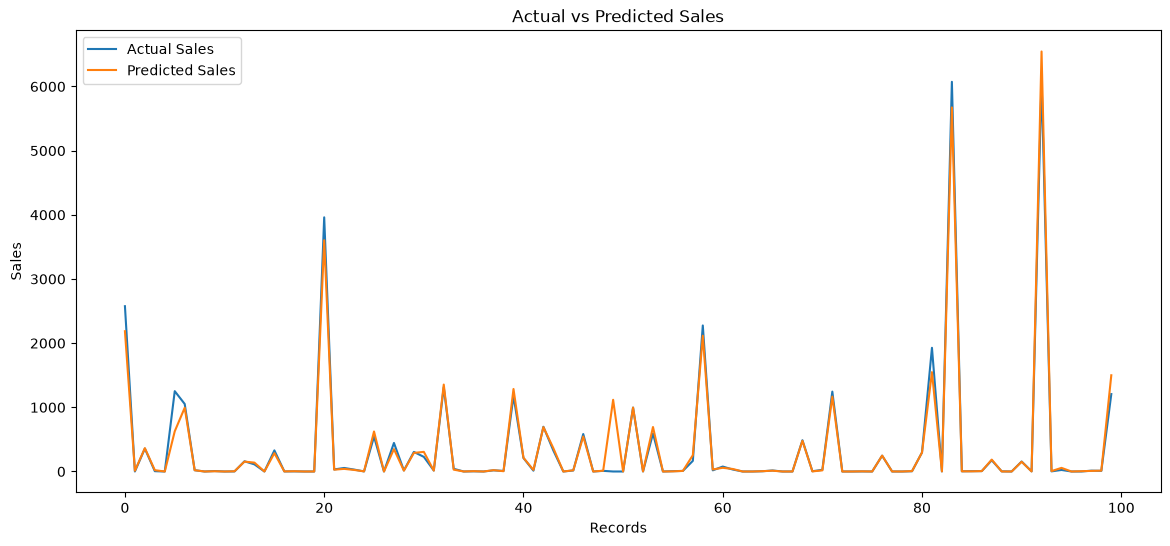

In [97]:
plt.figure(figsize=(14,6))
plt.plot(y_test.values[:100], label='Actual Sales')
plt.plot(yp[:100], label='Predicted Sales')
plt.title("Actual vs Predicted Sales")
plt.xlabel("Records")
plt.ylabel("Sales")
plt.legend()